In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

In [2]:
data = pd.read_csv("cifar-10.csv")

print(data.head())
print("Dataset Shape:", data.shape)

   pixel_0  pixel_1  pixel_2  pixel_3  pixel_4  pixel_5  pixel_6  pixel_7  \
0       59       43       50       68       98      119      139      145   
1      154      126      105      102      125      155      172      180   
2      255      253      253      253      253      253      253      253   
3       28       37       38       42       44       40       40       24   
4      170      168      177      183      181      177      181      184   

   pixel_8  pixel_9  ...  pixel_3063  pixel_3064  pixel_3065  pixel_3066  \
0      149      149  ...        58.0        65.0        59.0        46.0   
1      142      111  ...        42.0        67.0       101.0       122.0   
2      253      253  ...        83.0        80.0        69.0        66.0   
3       32       43  ...        39.0        59.0        42.0        44.0   
4      189      189  ...        88.0        85.0        82.0        83.0   

   pixel_3067  pixel_3068  pixel_3069  pixel_3070  pixel_3071  label  
0        

In [ ]:
# Handle Missing Values

In [3]:
# Convert columns into numeric values
data = data.apply(pd.to_numeric, errors='coerce')

# Remove rows having missing labels
data = data.dropna(subset=['label'])

# Replace missing pixel values with 0
data = data.fillna(0)

In [4]:
# Separate Features and Labels

In [5]:
pixel_columns = sorted(
    [col for col in data.columns if col.startswith('pixel_')],
    key=lambda x: int(x.split('_')[1])
)

X = data[pixel_columns].values
y = data['label'].astype(int).values

print("Features Shape:", X.shape)
print("Labels Shape:", y.shape)
print("Classes:", np.unique(y))

Features Shape: (10684, 3072)
Labels Shape: (10684,)
Classes: [0 1 2 3 4 5 6 7 8 9]


In [6]:
# Reshape Images

In [7]:
X = X.reshape(-1, 3, 32, 32)

X = X.transpose(0, 2, 3, 1)

print("Image Shape:", X.shape)

Image Shape: (10684, 32, 32, 3)


In [8]:
# Normalize Pixel Values

In [9]:
X = X / 255.0

In [10]:
# Display Sample Image

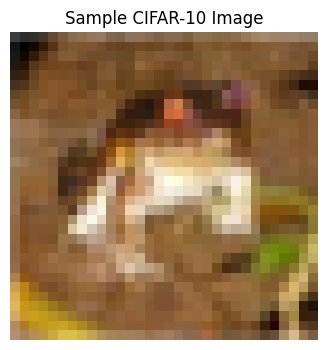

In [11]:
plt.figure(figsize=(4, 4))

plt.imshow(X[0])

plt.title("Sample CIFAR-10 Image")
plt.axis('off')

plt.show()

In [12]:
# Split Dataset

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (8547, 32, 32, 3)
Testing Data: (2137, 32, 32, 3)


In [14]:
# Define Class Names

In [15]:
class_names = [
    'Airplane', 'Automobile', 'Bird', 'Cat', 'Deer',
    'Dog', 'Frog', 'Horse', 'Ship', 'Truck'
]

In [ ]:
# Build CNN Model

In [16]:
model = Sequential([

    Conv2D(32, (3,3), activation='relu',
           input_shape=(32,32,3)),

    MaxPooling2D((2,2)),

    Conv2D(64, (3,3), activation='relu'),

    MaxPooling2D((2,2)),

    Flatten(),

    Dense(128, activation='relu'),

    Dense(10, activation='softmax')
])

model.summary()

C:\Users\Dell\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 30, 30, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 15, 15, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 13, 13, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 6, 6, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 2304)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         295,040 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 315,722 (1.20 MB)

 Trainable params: 315,722 (1.20 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# compile model

In [17]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [18]:
# Model Training

In [19]:
history = model.fit(
    X_train, y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.1
)

Epoch 1/10
121/121 ━━━━━━━━━━━━━━━━━━━━ 9s 48ms/step - accuracy: 0.3053 - loss: 1.9175 - val_accuracy: 0.3977 - val_loss: 1.6983
Epoch 2/10
121/121 ━━━━━━━━━━━━━━━━━━━━ 5s 43ms/step - accuracy: 0.4379 - loss: 1.5808 - val_accuracy: 0.4585 - val_loss: 1.5214
Epoch 3/10
121/121 ━━━━━━━━━━━━━━━━━━━━ 5s 45ms/step - accuracy: 0.4857 - loss: 1.4377 - val_accuracy: 0.4807 - val_loss: 1.4588
Epoch 4/10
121/121 ━━━━━━━━━━━━━━━━━━━━ 5s 43ms/step - accuracy: 0.5329 - loss: 1.3198 - val_accuracy: 0.5111 - val_loss: 1.4089
Epoch 5/10
121/121 ━━━━━━━━━━━━━━━━━━━━ 6s 45ms/step - accuracy: 0.5603 - loss: 1.2343 - val_accuracy: 0.5088 - val_loss: 1.3564
Epoch 6/10
121/121 ━━━━━━━━━━━━━━━━━━━━ 5s 43ms/step - accuracy: 0.5935 - loss: 1.1499 - val_accuracy: 0.5099 - val_loss: 1.4011
Epoch 7/10
121/121 ━━━━━━━━━━━━━━━━━━━━ 6s 47ms/step - accuracy: 0.6214 - loss: 1.0744 - val_accuracy: 0.5041 - val_loss: 1.3943
Epoch 8/10
121/121 ━━━━━━━━━━━━━━━━━━━━ 5s 44ms/step - accuracy: 0.6561 - loss: 0.9966 - val_accu

In [20]:
# Training and Testing Accuracy

In [ ]:
train_loss, train_acc = model.evaluate(X_train, y_train)

test_loss, test_acc = model.evaluate(X_test, y_test)

print("Training Accuracy:", train_acc * 100, "%")

print("Testing Accuracy:", test_acc * 100, "%")

In [21]:
# Plot Accuracy Graph

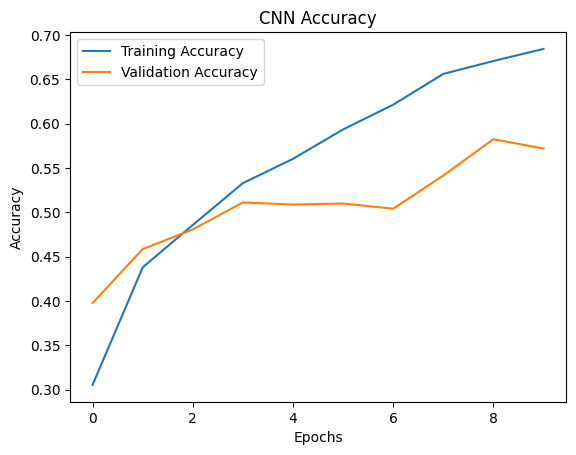

In [22]:
plt.plot(history.history['accuracy'], label='Training Accuracy')

plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title("CNN Accuracy")

plt.xlabel("Epochs")

plt.ylabel("Accuracy")

plt.legend()

plt.show()

In [23]:
# Plot Loss Graph

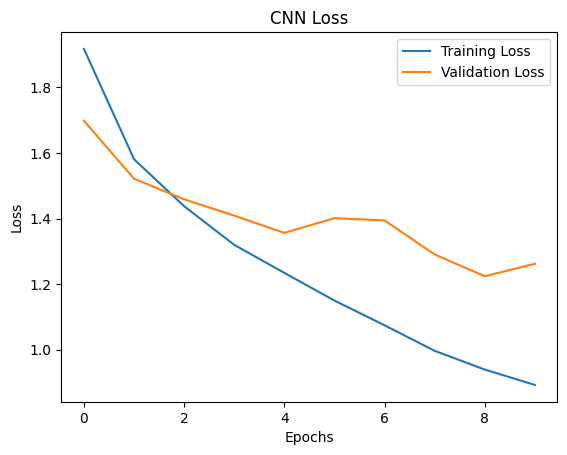

In [24]:
plt.plot(history.history['loss'], label='Training Loss')

plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title("CNN Loss")

plt.xlabel("Epochs")

plt.ylabel("Loss")

plt.legend()

plt.show()

In [25]:
# Generate Predictions

In [26]:
y_pred = model.predict(X_test)

predicted_labels = np.argmax(y_pred, axis=1)

67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step


In [27]:
# Display Five Predictions with Images

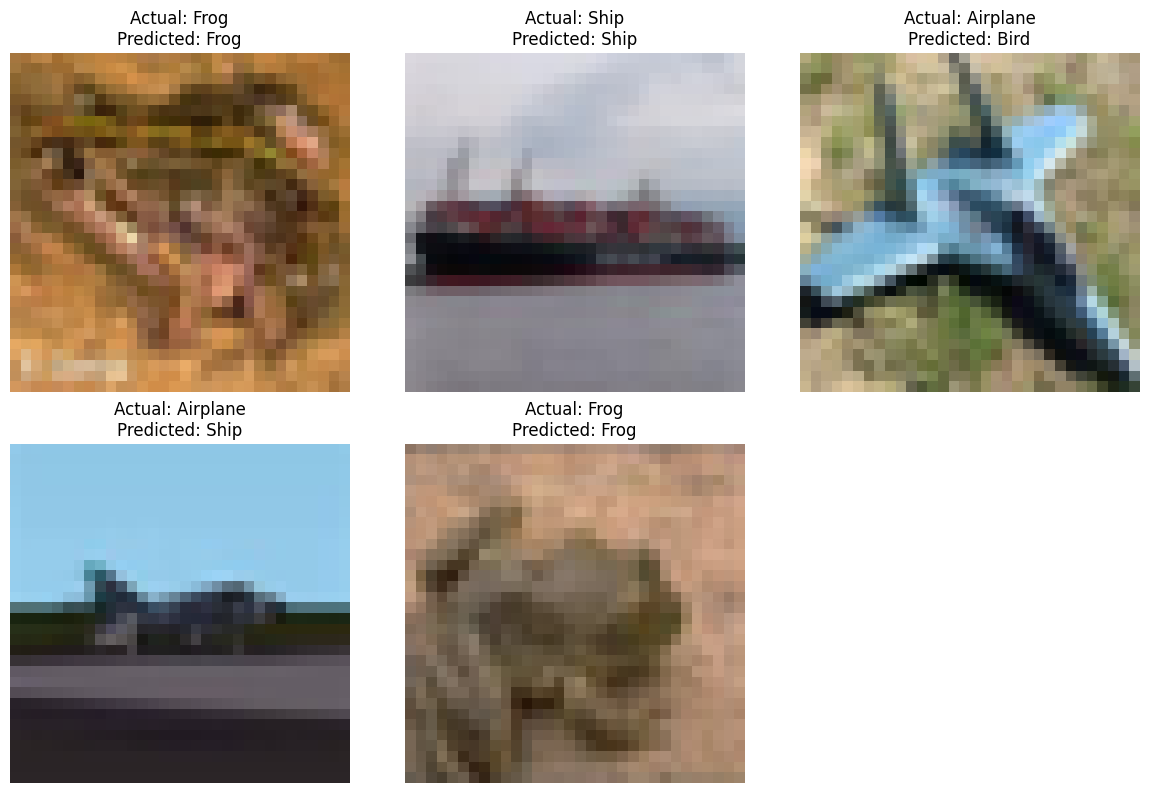

In [28]:
plt.figure(figsize=(12, 8))

for i in range(5):

    plt.subplot(2, 3, i+1)

    plt.imshow(X_test[i])

    actual = class_names[y_test[i]]

    predicted = class_names[predicted_labels[i]]

    plt.title("Actual: " + actual + "\nPredicted: " + predicted)

    plt.axis('off')

plt.tight_layout()

plt.show()

### Confusion Matrix 

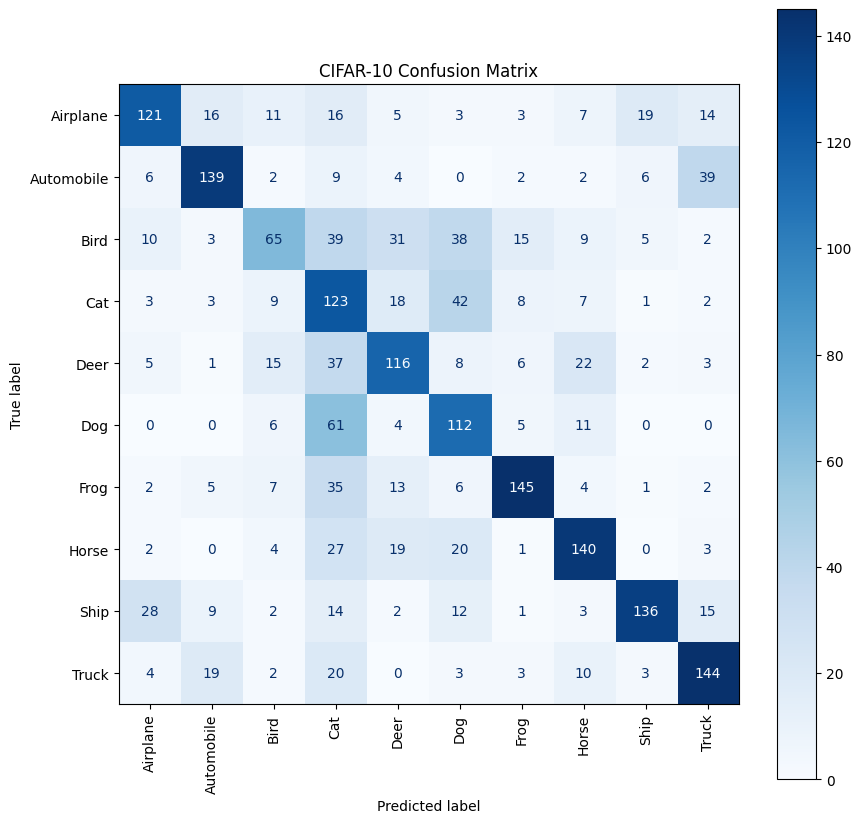

In [29]:
cm = confusion_matrix(y_test, predicted_labels)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(10, 10))

display.plot(
    cmap='Blues',
    ax=ax,
    xticks_rotation='vertical'
)

plt.title("CIFAR-10 Confusion Matrix")

plt.show()

Here are **25 important code-based viva questions with answers** covering both Practical 19 and Practical 21 – CNN using CIFAR-10.

## CNN – CIFAR-10: 25 Viva Questions

**1. What is CIFAR-10?**  
CIFAR-10 is an image dataset containing 10 different object categories.

**2. What are the 10 classes in CIFAR-10?**  
Airplane, Automobile, Bird, Cat, Deer, Dog, Frog, Horse, Ship and Truck.

**3. Which function is used to load CIFAR-10?**  
`cifar10.load_data()` – It loads the CIFAR-10 dataset.

**4. How many training and testing images are available?**  
50,000 training images and 10,000 testing images.

**5. What is the size of each CIFAR-10 image?**  
32 × 32 pixels with 3 RGB color channels.

**6. What does RGB stand for?**  
Red, Green and Blue.

**7. Why do we divide pixel values by 255?**  
To normalize pixel values from 0–255 to 0–1.

**8. What is the purpose of `reshape(-1, 32, 32, 3)`?**  
It arranges images into the CNN input format: height, width and 3 color channels. If the images are already in this shape, reshaping is unnecessary.

**9. What is `Conv2D()`?**  
It is a convolutional layer that extracts features such as edges, shapes and patterns from images.

**10. What does `Conv2D(32, (3,3), activation='relu')` mean?**  
It creates 32 filters, each of size 3 × 3, using ReLU activation.

**11. What is a filter or kernel in CNN?**  
It is a small matrix that moves over an image to detect important features.

**12. What is the purpose of `MaxPooling2D((2,2))`?**  
It reduces feature-map dimensions by selecting the maximum value from each 2 × 2 region.

**13. What is the difference between Conv2D and MaxPooling2D?**  
Conv2D extracts features, whereas MaxPooling2D reduces feature-map size.

**14. What is the purpose of `Flatten()`?**  
It converts 2D feature maps into a 1D vector before passing them to Dense layers.

**15. What is a Dense layer?**  
It is a fully connected layer where every neuron connects to all neurons in the previous layer.

**16. Why do we use `Dense(10, activation='softmax')`?**  
Because CIFAR-10 has 10 output classes. Softmax calculates the probability of each class.

**17. What is the purpose of `model.compile()`?**  
It configures the model using an optimizer, loss function and evaluation metric.

**18. Which optimizer is commonly used in this practical?**  
Adam optimizer. It updates model weights to reduce prediction errors.

**19. Which loss function is used for CIFAR-10 classification?**  
Sparse categorical crossentropy, because the class labels are represented as integers.

**20. What is the purpose of `model.fit()`?**  
It trains the CNN model using training images and their labels.

**21. What is the purpose of `model.evaluate(X_test, y_test)`?**  
It evaluates the trained model on testing images and returns test loss and accuracy.

**22. What does `model.predict(X_test)` do?**  
It predicts the class probabilities for the test images.

**23. What is a confusion matrix?**  
It is a table that compares actual class labels with predicted class labels to show correct and incorrect classifications.

**24. What does `confusion_matrix(y_test, y_pred)` do?**  
It generates a confusion matrix by comparing actual labels (`y_test`) with predicted labels (`y_pred`).

**25. What does the diagonal of a confusion matrix represent?**  
Correct predictions for each class. Higher diagonal values generally indicate better classification performance.

---

### Important code statements to remember

| Code | Purpose |
|---|---|
| `cifar10.load_data()` | Loads CIFAR-10 dataset |
| `X_train / 255.0` | Normalizes images |
| `Conv2D()` | Extracts image features |
| `MaxPooling2D()` | Reduces feature-map size |
| `Flatten()` | Converts feature maps into 1D |
| `Dense(10, activation='softmax')` | Creates 10 output classes |
| `model.compile()` | Configures the model |
| `model.fit()` | Trains the model |
| `model.evaluate()` | Evaluates test accuracy |
| `model.predict()` | Predicts image classes |
| `np.argmax()` | Finds the predicted class index |
| `confusion_matrix()` | Generates confusion matrix |
| `ConfusionMatrixDisplay()` | Displays confusion matrix |

### Important difference between Practical 19 and 21

- **Practical 19:** Focuses on CNN implementation, image classification and testing accuracy.
- **Practical 21:** Focuses on evaluating classification performance using a confusion matrix.

**Remember:** CIFAR-10 contains colored 32 × 32 images, whereas Fashion-MNIST and handwritten MNIST contain grayscale 28 × 28 images.